# 04 - Body part and game state

**Goal:** check two football features before they go into the model.
1. *Body part:* do headers really score more than foot shots?
2. *Game state:* does the score at the moment of the shot change the goal rate?

Open-play shots only (`shot_type == "shot"`). Input: `data/processed/shots_game_state.csv`
(run `src/game_state.py` first).

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path("..").resolve() / "src"))
from eda_utils import goal_rate_table, plot_goal_rate

FIG_DIR = Path("..") / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

FOOT_COLOR = "#2a78d6"
HEAD_COLOR = "#eb6834"


def save(fig, name):
    """Save a figure into reports/figures."""
    fig.savefig(FIG_DIR / name, dpi=150, bbox_inches="tight")


shots_all = pd.read_csv("../data/processed/shots_game_state.csv")
shots = shots_all[shots_all["shot_type"] == "shot"].copy()   # open-play shots only

# Distance bands used in both sections (16+ m merged: almost no headers from far)
BINS = [0, 8, 12, 16, 100]
LABELS = ["0-8 m", "8-12 m", "12-16 m", "16+ m"]
shots["dist_band"] = pd.cut(shots["distance"], BINS, labels=LABELS)

print("Open-play shots:", len(shots))

Open-play shots: 8451


## 1. Body part

Headers seem to score more than foot shots overall. But headers are taken much closer to goal,
so the overall number mixes two effects. We compare them **inside the same distance band**.

In [2]:
shots["body"] = np.where(shots["header"], "header", "foot")

print("Overall goal rate:")
display(goal_rate_table(shots, "body").round(3))

print("Median distance (m):")
display(shots.groupby("body")["distance"].median().round(1))

Overall goal rate:


,shots,goals,goal_rate,ci_low,ci_high
body,,,,,
foot,7134,736,0.103,0.096,0.110
header,1317,178,0.135,0.118,0.155


Median distance (m):


body
foot      18.9
header    10.3
Name: distance, dtype: float64

foot                                header                         \
          shots goals goal_rate ci_low ci_high  shots goals goal_rate ci_low   
dist_band                                                                      
0-8 m       360   165     0.458  0.408   0.510    337    92     0.273  0.228   
8-12 m      725   168     0.232  0.202   0.264    587    69     0.118  0.094   
12-16 m    1548   223     0.144  0.127   0.162    344    15     0.044  0.027   
16+ m      4501   180     0.040  0.035   0.046     49     2     0.041  0.011   

                   
          ci_high  
dist_band          
0-8 m       0.323  
8-12 m      0.146  
12-16 m     0.071  
16+ m       0.137

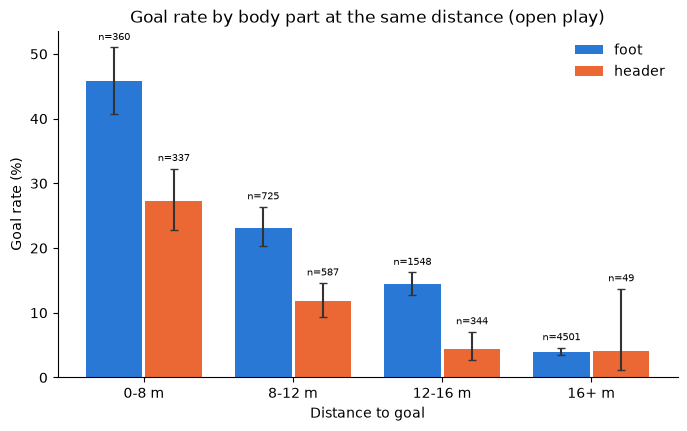

In [3]:
by_band = {b: goal_rate_table(shots[shots["body"] == b], "dist_band") for b in ["foot", "header"]}
display(pd.concat(by_band, axis=1).round(3))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(LABELS))
width = 0.38
for i, (body, color) in enumerate([("foot", FOOT_COLOR), ("header", HEAD_COLOR)]):
    t = by_band[body].reindex(LABELS)
    rate = t["goal_rate"] * 100
    err = [rate - t["ci_low"] * 100, t["ci_high"] * 100 - rate]
    pos = x + (i - 0.5) * (width + 0.02)
    ax.bar(pos, rate, width, color=color, label=body, yerr=err, capsize=3, ecolor="#333333")
    for p, n, hi in zip(pos, t["shots"], t["ci_high"]):
        if pd.notna(n):
            ax.text(p, hi * 100 + 0.8, f"n={int(n)}", ha="center", va="bottom", fontsize=7)

ax.set_xticks(x, LABELS)
ax.set_xlabel("Distance to goal")
ax.set_ylabel("Goal rate (%)")
ax.set_title("Goal rate by body part at the same distance (open play)")
ax.legend(frameon=False)
save(fig, "16_goal_rate_body_part_by_distance.png")
plt.show()

**Reading:** at every distance a header scores **less** than a foot shot. The overall
"headers score more" result only appears because headers are taken from closer.
Distance is a **confounding variable** here. In the model, `header` must be used together
with `distance`, otherwise its effect gets the wrong sign.

## 2. Game state

`game_state` is the score of the shooting team **before** the shot: winning, drawing or losing.

,shots,goals,goal_rate,ci_low,ci_high
game_state,,,,,
losing,2208,205,0.093,0.081,0.106
drawing,4048,405,0.100,0.091,0.110
winning,2195,304,0.138,0.125,0.154


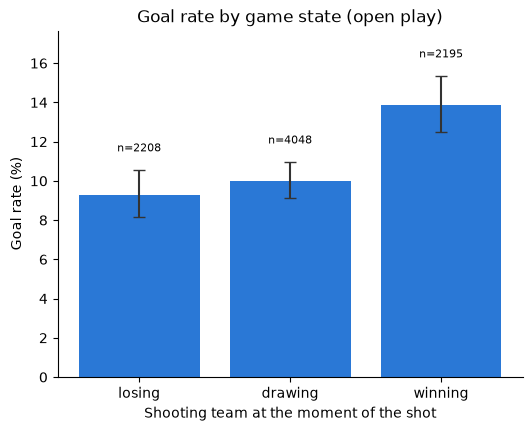

In [4]:
ORDER = ["losing", "drawing", "winning"]
state_table = goal_rate_table(shots, "game_state").reindex(ORDER)
display(state_table.round(3))

fig, ax = plt.subplots(figsize=(6, 4.5))
plot_goal_rate(ax, state_table, title="Goal rate by game state (open play)",
               xlabel="Shooting team at the moment of the shot", color=FOOT_COLOR)
save(fig, "17_goal_rate_game_state.png")
plt.show()

Is the difference just distance again? Check the median distance, the share of counter
attacks, and the goal rate inside the same distance band.

In [5]:
summary = shots.groupby("game_state").agg(
    shots=("id", "size"),
    median_distance=("distance", "median"),
    counter_share=("counter_attack", "mean"),
    header_share=("header", "mean"),
).reindex(ORDER)
display(summary.round(3))

band_rate = shots.pivot_table(index="dist_band", columns="game_state", values="is_goal",
                              aggfunc="mean", observed=True)[ORDER]
display((band_rate * 100).round(1))

,shots,median_distance,counter_share,header_share
game_state,,,,
losing,2208,16.829,0.033,0.197
drawing,4048,17.456,0.046,0.160
winning,2195,16.494,0.075,0.108


game_state,losing,drawing,winning
dist_band,,,
0-8 m,32.8,33.8,46.7
8-12 m,13.3,18.7,21.8
12-16 m,12.6,11.9,13.7
16+ m,2.9,3.4,6.3


**Reading:** the leading team scores more often even from the same distance.
- **The opponent pushes forward.** A losing team attacks with more players and leaves space behind,
  so the leading team gets cleaner chances. This fits the higher counter-attack share when winning.
- **Psychology.** The leading team finishes more calmly and confidently. This data cannot measure it.

Decision for Day 4: build the baseline without game state first, then add it and check
whether the model improves.

## 3. Checks on `game_state.py`

In [6]:
# 1) Opening match Arsenal (1609) 4-3 Leicester (1631): last goal is scored at 4-3 or 3-3
m = shots_all[shots_all["matchId"] == 2499719]
display(m[m["is_goal"]][["teamId", "matchPeriod", "eventSec", "goals_for", "goals_against"]])

# 2) A shot never counts itself: inside a match, the total score before each goal
#    must go up by at least 1 from one goal to the next
goal_shots = shots_all[shots_all["is_goal"]].sort_values(["matchId", "matchPeriod", "eventSec"])
total = goal_shots["goals_for"] + goal_shots["goals_against"]
step = total.groupby(goal_shots["matchId"]).diff().dropna()
print("Goals where the score did not go up:", (step < 1).sum())

,teamId,matchPeriod,eventSec,goals_for,goals_against
0,1609,1H,94.595788,0,0
2,1631,1H,254.745027,0,1
10,1631,1H,1710.855093,1,1
14,1609,1H,2815.900791,1,2
18,1631,2H,634.312236,2,2
30,1609,2H,2231.119656,2,3
32,1609,2H,2374.620655,3,3


Goals where the score did not go up: 0
